# Exercises for Section 4.2 Multiple linear regression

This notebook contains the exercises
from [Section 4.2 Multiple linear regression]()
in the **No Bullshit Guide to Statistics**.

### Notebook setup

In [1]:
# Ensure required Python modules are installed
%pip install --quiet numpy scipy seaborn pandas ministats


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Figures setup
plt.clf()  # needed otherwise `sns.set_theme` doesn't work
sns.set_theme(
    context="paper",
    style="whitegrid",
    palette="colorblind",
    rc={"figure.figsize": (6, 1.6)},
)
%config InlineBackend.figure_format = "retina"

<Figure size 640x480 with 0 Axes>

In [4]:
# Simplified int and float __repr__
np.set_printoptions(legacy='1.25')

In [5]:
# Check the `ministats` version to make sure all the datasets will be in place.
import ministats
from packaging.version import Version

if Version(ministats.__version__) <= Version("0.5.19"):
    print("You have version", ministats.__version__, "of the `ministats` library.")
    print("You must use ministats version 0.5.20 or later.")
    print("Run the following command in a new notebook cell:")
    print("   %pip install --upgrade ministats")

In [6]:
# %pip install --upgrade ministats

In [7]:
# Download datasets/ directory if necessary
from ministats import ensure_datasets
ensure_datasets()

datasets/ directory already exists.


$\def\stderr#1{\mathbf{se}_{#1}}$
$\def\stderrhat#1{\hat{\mathbf{se}}_{#1}}$
$\def\Mean{\textbf{mean}}$
$\def\Var{\textbf{var}}$
$\def\Std{\textbf{std}}$
$\def\Freq{\textbf{freq}}$
$\def\RelFreq{\textbf{relfreq}}$
$\def\CI#1{\textbf{CI}_{#1}}$
$\def\CIL#1{\textbf{L}_{#1}}$
$\def\CIU#1{\textbf{U}_{#1}}$
$\def\ci#1{\textbf{ci}_{#1}}$
$\def\cil#1{\textbf{l}_{#1}}$
$\def\ciu#1{\textbf{u}_{#1}}$
$\def\DMeans{\textbf{dmeans}}$
$\def\Prop{\textbf{prop}}$
$\def\DProps{\textbf{dprops}}$
$\def\Err{ {\Large \varepsilon}}$
$\def\calN{\mathcal{N}}$
$\def\Tdist{\mathcal{T}}$
$\def\Expon{\mathrm{Expon}}$

(this cell contains the macro definitions like $\stderr{\overline{\mathbf{x}}}$, $\stderrhat{}$, $\Mean$, ...)

## Exercises

### E4.8

<!-- {exercise:doctors-fit-LM-score-vs-alc-and-weed} -->

Use `statsmodels` to fit a linear model for the doctors' sleep `score` variable
based on the alcohol (`alc`) and weed (`weed`) consumption data
from the [doctors dataset](https://noBSstats.com/datasets/doctors.csv).
Interpret the estimated slope parameters $\widehat{\beta}_{\texttt{alc}}$ and $\widehat{\beta}_{\texttt{weed}}$
in your own words.

Hint: Use the formula   `"score 1 + alc + weed"`   for the model.


In [8]:
import pandas as pd
doctors = pd.read_csv("datasets/doctors.csv")
doctors.head(3)

,permit,loc,work,hours,caf,alc,weed,exrc,score
0,93273,rur,hos,21,2,0,5.0,0.0,63
1,90852,urb,cli,74,26,20,0.0,4.5,16
2,92744,urb,hos,63,25,1,0.0,7.0,58


In [10]:
# Fit the linear model
import statsmodels.formula.api as smf
lm_score = smf.ols("score ~ 1 + alc + weed", data=doctors).fit()
lm_score.params

Intercept    69.304211
alc          -1.773418
weed         -0.448502
dtype: float64

The estimated model parameters are
$\widehat{\beta}_{0} = 69.3$,
$\widehat{\beta}_{\texttt{alc}} = -1.77$,
and $\widehat{\beta}_{\texttt{weed}} = -0.45$.
The estimated slope $\widehat{\beta}_{\texttt{alc}}$ tells us that,
according to the model,
each additional standard unit of alcohol consumed
is associated with a decrease of $1.77$ units in sleep score,
on average,
assuming `weed` consumption is held constant.
Similarly,
smoking an additional gram of weed per week
is associated with decrease of $0.45$ units in sleep score,
on average,
assuming `alc` consumption is held constant.

### E4.9

<!-- {exercise:OECD-lifesat-vs-gdp-and-educ} -->

Fit a linear model for life satisfaction (`lifesat`)
in the OECD Better Life Index dataset
([`datasets/oecd_bli.csv`](https://noBSstats.com/datasets/oecd_bli.csv)).
Use the variables
gross domestic product per capita (`gdp`)
and education (`educ`) as predictors.
Generate partial regression plots for the two predictor variables.

Hint: Use the `ministats` function   `plot_partreg`   for the plots.

In [11]:
oecd_bli = pd.read_csv("datasets/oecd_bli.csv")
oecd_bli.head(3)

,Country,educ,income,lifesat,salary,gdp
0,Mexico,42.0,16269.0,6.0,16230.0,23659.0
1,Greece,76.0,20791.0,5.8,27207.0,38397.0
2,Slovak Republic,92.0,21149.0,6.5,23619.0,40586.0


In [13]:
# Fit the linear model
import statsmodels.formula.api as smf
lm_lifesat = smf.ols("lifesat ~ 1 + gdp + educ", data=oecd_bli).fit()
lm_lifesat.params

Intercept    4.764315
gdp          0.000030
educ         0.003061
dtype: float64

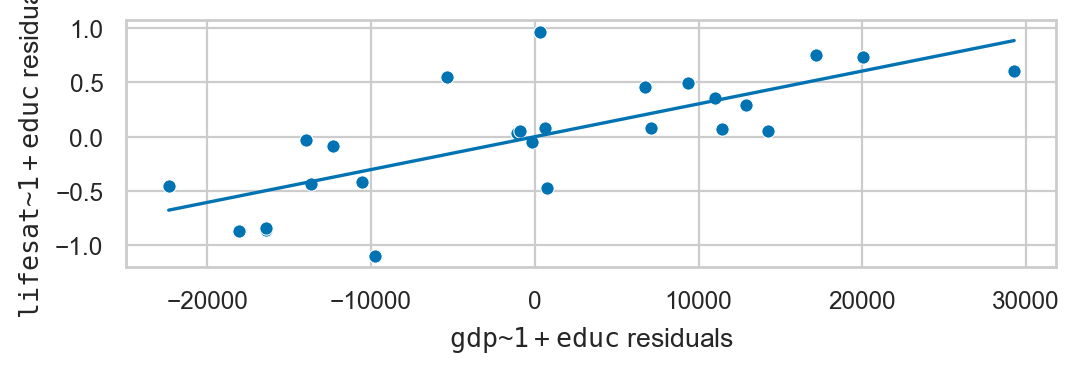

In [15]:
# Partial regression plot for the predictor `gdp`
from ministats import plot_partreg
plot_partreg(lm_lifesat, pred="gdp");

The first plot shows a trend of increasing life satisfaction as a function of GDP.
It seems that living in a rich country is correlated with life satisfaction,
for the same level of education.

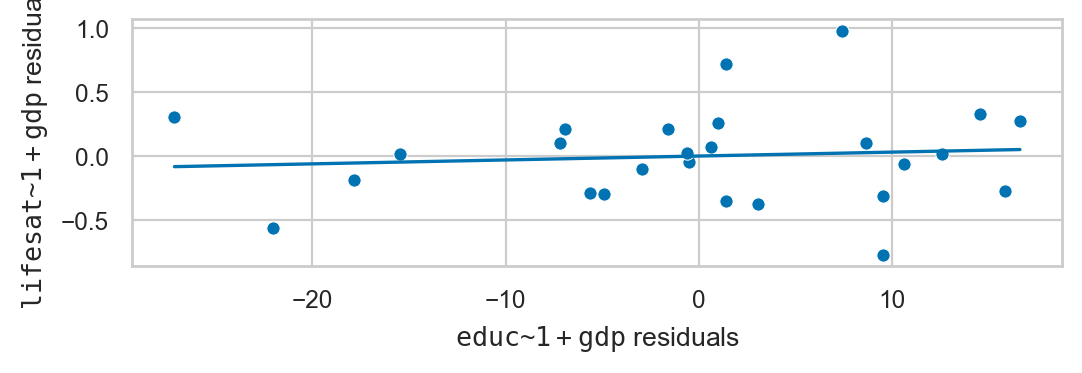

In [17]:
# Partial regression plot for the predictor `educ`
plot_partreg(lm_lifesat, pred="educ");

The second plot doesn't show a strong trend:
education doesn't seem to have as big effect on life satisfaction,
after controlling for GDP.

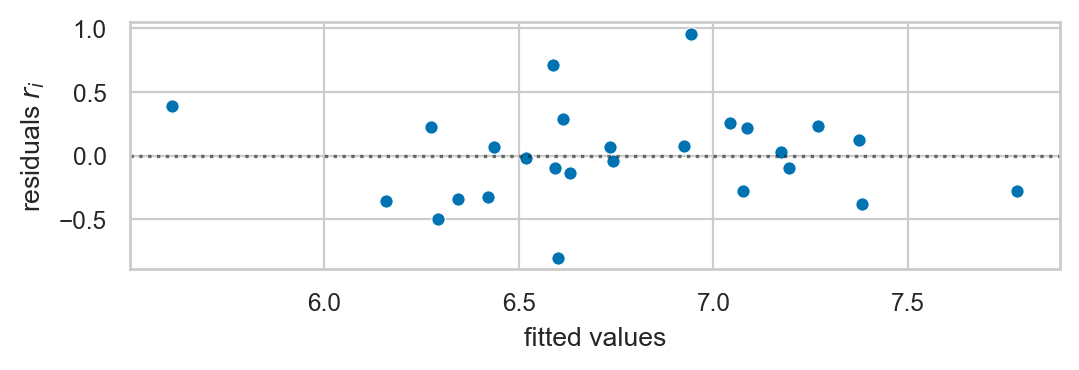

In [18]:
# Bonus: plot the model's residuals
from ministats import plot_resid
plot_resid(lm_lifesat);

### E4.10

<!-- {exercise:marketing-sales-vs-youtube-facebook-and-newspaper} -->

Let's revisit the marketing dataset that we saw in the previous section,
but this time include all predictors.

**a)** Fit a model for the relationship between the predictors
`youtube`, `facebook`, and `newspaper`
and the outcome variable `sales`.

**b)** Use the `ministats` function `plot_resid` to plot the residuals.

**c)** Use `plot_partreg` to generate three partial regression plots.


In [19]:
marketing = pd.read_csv("datasets/marketing.csv")
marketing.head(3)

,youtube,facebook,newspaper,sales
0,276.12,45.36,83.04,26.52
1,53.40,47.16,54.12,12.48
2,20.64,55.08,83.16,11.16


In [21]:
# a) Fit the linear model
import statsmodels.formula.api as smf
sales_formula = "sales ~ 1 + youtube + facebook + newspaper"
lm_sales = smf.ols(sales_formula, data=marketing).fit()
lm_sales.params

Intercept    3.526667
youtube      0.045765
facebook     0.188530
newspaper   -0.001037
dtype: float64

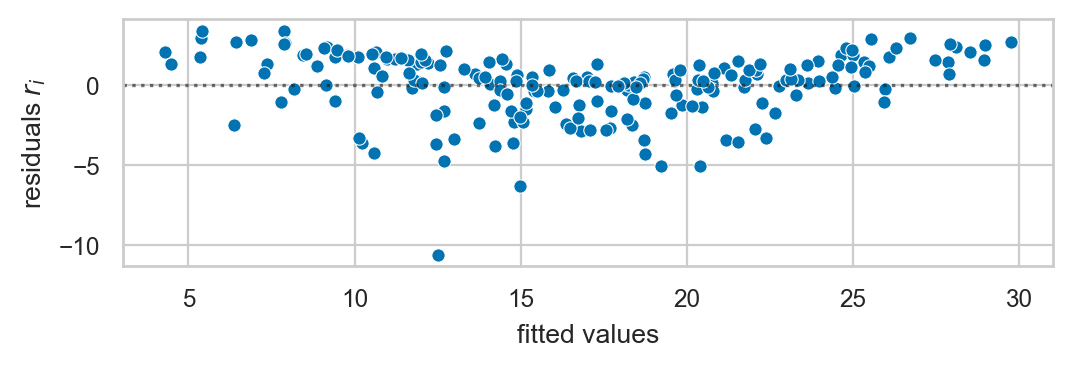

In [23]:
# b) Plot the residuals
from ministats import plot_resid
plot_resid(lm_sales);

The residual plot seems to show a quadratic pattern in the residuals,
suggesting a violation of the linearity assumption $\mathbf{(LIN)}$.
However,
the non-linearity is very slight so it doesn't invalidate our use of a linear model.

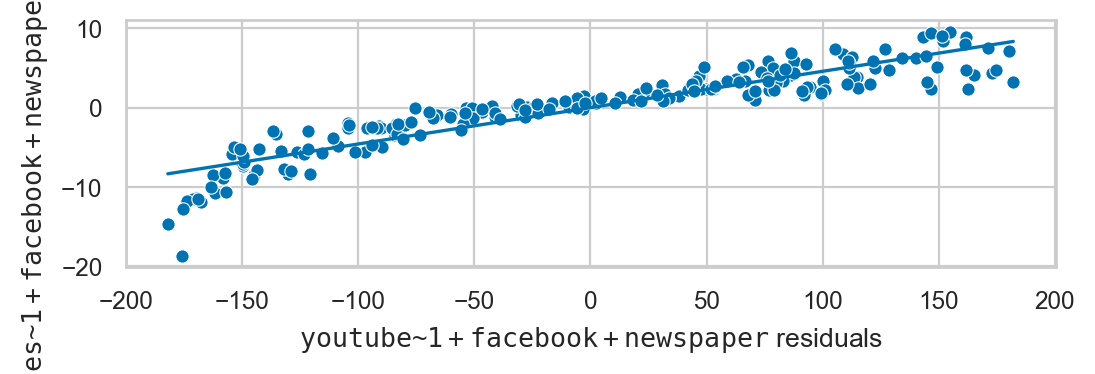

In [25]:
# c) Partial regression plot for the predictor `youtube` 
from ministats import plot_partreg
plot_partreg(lm_sales, pred="youtube");

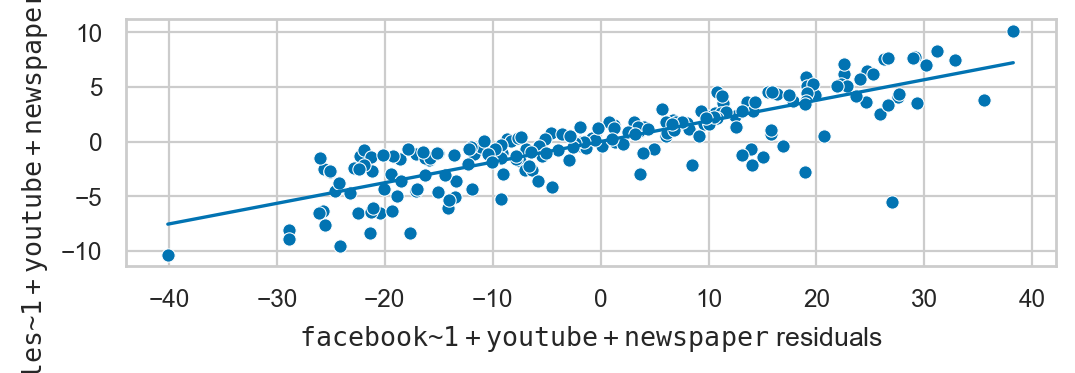

In [27]:
# c) Partial regression plot for the predictor `facebook` 
plot_partreg(lm_sales, pred="facebook");

The partial regression plots
show that ad spend on `youtube` and `facebook`
are positively associated with sales after controlling for the other predictors.

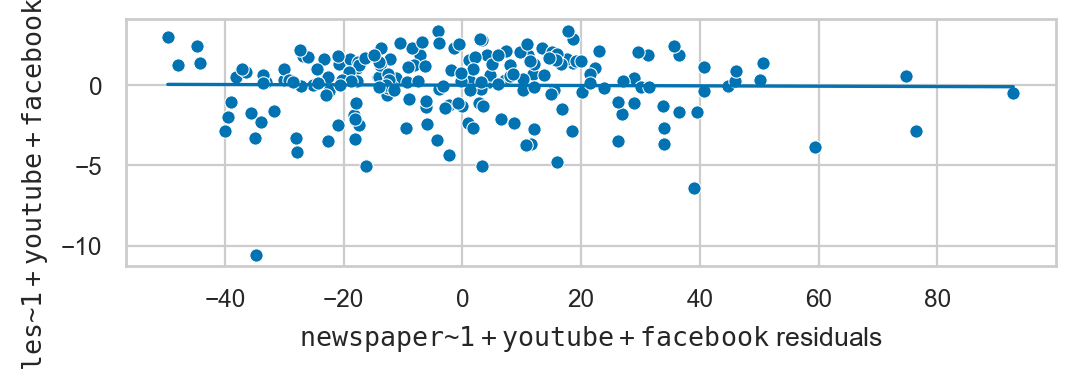

In [29]:
# c) Partial regression plot for the predictor `newspaper` 
plot_partreg(lm_sales, pred="newspaper");

In contrast,
`newspaper` advertisement
shows little linear association with sales,
after controlling for the other two predictors.

### E4.11

<!-- {exercise:Duncan-prestige-vs-income-and-education} -->

Fit a multiple linear regression model to the
[`Duncan` occupational prestige dataset](https://rdrr.io/cran/carData/man/Duncan.html)
to investigate the link between `income` and `education`
predictors and the `prestige` outcome variable.

Hint: Use the function `get_rdataset` defined in `statsmodels` to load the data.

In [30]:
from statsmodels.datasets import get_rdataset
Duncan = get_rdataset("Duncan", "carData").data
Duncan.head()

,type,income,education,prestige
rownames,,,,
accountant,prof,62,86,82
pilot,prof,72,76,83
architect,prof,75,92,90
author,prof,55,90,76
chemist,prof,64,86,90


In [32]:
import statsmodels.formula.api as smf
prestige_formula = "prestige ~ 1 + income + education"
lm_prestige = smf.ols(prestige_formula, data=Duncan).fit()
lm_prestige.params

Intercept   -6.064663
income       0.598733
education    0.545834
dtype: float64

The best fit linear model is $\widehat{\texttt{prestige}} = -6.06 + 0.60\,\texttt{income} + 0.55\,\texttt{education}$.

### E4.12

<!-- {exercise:synthetic-data-two-predictors} -->

Generate a synthetic dataset $[\mathbf{x}_1, \mathbf{x}_2, \mathbf{y}]$
with $n=50$ observations from the random variables
$X_1 \sim \mathcal{N}(0,1)$,
$X_2 \sim \mathcal{N}(0,3)$,
and $Y \sim 10 + 3X_1 + 5X_2 + \mathcal{N}(0,1)$.
Fit the linear model to this dataset
based on the formula  `"y 1 + x1 + x2"` 
and check that you approximately recover model parameters
$\beta_0 = 10$, $\beta_1 = 3$, and $\beta_2 = 5$.

Hint: Create computer models for $X_1$, $X_2$,
and the $\mathcal{N}(0,1)$ error term based on the `norm` model family from `scipy.stats`.

Hint: Use the code   `pd.DataFrame({"x1":x1s,"x2":x2s,"y":ys})` 
to "package" the observations `x1s`, `x2s`, and `ys` into a data frame.

In [34]:
# Create computer models for the X1, X2, and the noise
from scipy.stats import norm
rvX1 = norm(0,1)
rvX2 = norm(0,3)
rvZ = norm(0,1)

# Set the random seed to a particular value to get a reproducible result
np.random.seed(48)

# Generate the random observations from X1, X2, and the noise
x1s = rvX1.rvs(50)
x2s = rvX2.rvs(50)
noise = rvZ.rvs(50)

# Generate the observations from the outcome variable
beta0, beta1, beta2 = 10, 3, 5
ys = beta0 + beta1*x1s + beta2*x2s + noise

# Package x1s, x2s, and ys as a pd.DataFrame
df_xys = pd.DataFrame({"x1":x1s, "x2":x2s, "y":ys})
df_xys.head(3)

,x1,x2,y
0,-0.993631,-2.865764,-9.021473
1,-1.063401,4.552381,28.652382
2,-0.638076,2.321520,19.148702


In [35]:
# Fit linear model
import statsmodels.formula.api as smf
lm_xys = smf.ols("y ~ 1 + x1 + x2", data=df_xys).fit()

# Show the parameter estimates
lm_xys.params

Intercept    10.148865
x1            2.970458
x2            5.037181
dtype: float64

The parameter estimates
$\widehat{\beta}_{0} = 10.15$, $\widehat{\beta}_{1} = 2.97$, and $\widehat{\beta}_{2} = 5.04$
are close to the true parameters
that we used to create the synthetic data,
$\beta_0 = 10$, $\beta_1 = 3$, and $\beta_2 = 5$.